# Checking the variance of temperature:
### to estimate how many ensemble members to use for internal variability analysis  
Not only will we check the global mean variability but also spatial variability

In [1]:
import os
import numpy as np
import xarray as xr
from utils.utils import get_scenario_config

In [2]:
# === Path config ===
TEMP_DIR = "/glade/derecho/scratch/arielm/Olympics/ARISE-SAI-1.5-downscaled/TREFHT/SSP2-4.5/"

In [3]:
# Set up
model = "CESM2"
scenario = "SSP245_LE"

configs = get_scenario_config(model, scenario)
ensemble_members = configs["ensemble_members"]  # 10 ensembles
years = configs["years"]  # 2050-2055, 6 years

In [4]:
# Concat files into years, ensemble_members, latitude, longitude
all_years = []
for year in years:
    ensembles = []
    for ens_num in ensemble_members:
        print(year, f"{ens_num:02d}")
        da = xr.open_dataarray(TEMP_DIR + f"bc_TREFHT_{scenario[:-3]}_ens0{ens_num:02d}_{year}.nc")
        ensembles.append(da.mean("time"))
    temp_ens = xr.concat(ensembles, dim=xr.DataArray(np.arange(1, len(ensembles)+1), dims="ensemble", name="ensemble"))
    all_years.append(temp_ens)
temp_all = xr.concat(all_years, dim=xr.DataArray(years, dims="year", name="year"))

2050 01
2050 02
2050 03
2050 04
2050 05
2050 06
2050 07
2050 08
2050 09
2050 10
2051 01
2051 02
2051 03
2051 04
2051 05
2051 06
2051 07
2051 08
2051 09
2051 10
2052 01
2052 02
2052 03
2052 04
2052 05
2052 06
2052 07
2052 08
2052 09
2052 10
2053 01
2053 02
2053 03
2053 04
2053 05
2053 06
2053 07
2053 08
2053 09
2053 10
2054 01
2054 02
2054 03
2054 04
2054 05
2054 06
2054 07
2054 08
2054 09
2054 10
2055 01
2055 02
2055 03
2055 04
2055 05
2055 06
2055 07
2055 08
2055 09
2055 10


Check global means for "raw" temperature data and "anomaly" data

In [5]:
# Calculate latitude weighting
weights = np.cos(np.deg2rad(temp_all.latitude))
weights.name = "weights"

In [6]:
# Compute the latitude-weighted mean over lat and lon
weighted_mean = temp_all.weighted(weights).mean(("latitude", "longitude"))
# plot to see trend
# weighted_mean.mean("ensemble").plot()

In [7]:
# Calculate the anomaly - minus ensemble means
temp_anomaly = temp_all - temp_all.mean("ensemble")

# Compute the latitude-weighted mean over lat and lon
weighted_mean = temp_anomaly.weighted(weights).mean(("latitude", "longitude"))
# plot to see trend
# weighted_mean.mean("ensemble").plot()

Stack all ensemble members and years together for larger n

In [8]:
stacked = temp_anomaly.stack(n=("ensemble", "year"))

Calculate how the global mean temperature variance changes across number of ensemble members

In [9]:
variance_across_ens = []
for i in range(len(stacked.n)):
    # print(stacked.isel(n=i).n.values)
    global_mean = stacked.weighted(weights).mean(("latitude", "longitude"))
    variance_across_ens.append(global_mean[:i].var().values)

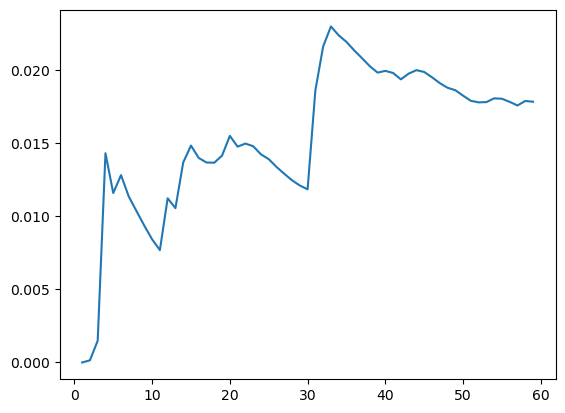

In [10]:
import matplotlib.pyplot as plt
plt.plot(variance_across_ens)

In [11]:
N = temp_all.sizes["ensemble"]

# Subtracting the ensemble mean uses up 1 degree of freedom per year, so the
# anomaly variance is biased low by (N-1)/N. Rescale to correct it.
anom = (temp_all - temp_all.mean("ensemble")) * np.sqrt(N / (N - 1))

stacked = (
    anom.stack(n=("year", "ensemble"))
        .transpose("n", "latitude", "longitude")
        .load()                      # pull into memory ONCE (it is lazy right now)
)
n_total = stacked.sizes["n"]
weights = np.cos(np.deg2rad(stacked.latitude))

In [18]:
def cumvar(x, ddof=1):
    """Sample variance of the first k samples along axis 0, for k = 2..n.
    Vectorised via cumulative sums (no loop over k, no recomputation)."""
    x = np.asarray(x, dtype=np.float64)
    k = np.arange(1, x.shape[0] + 1).reshape((-1,) + (1,) * (x.ndim - 1))
    s1 = np.cumsum(x, axis=0)
    s2 = np.cumsum(x ** 2, axis=0)
    return ((s2 - s1 ** 2 / k) / (k - ddof))[1:]


def pick(da, lat, lon):
    if float(da.longitude.max()) > 180:      # handle 0-360 grids
        lon = lon % 360
    return da.sel(latitude=lat, longitude=lon, method="nearest")

/glade/derecho/scratch/awells/tmp/ipykernel_23236/439536209.py:8: RuntimeWarning: invalid value encountered in divide
  return ((s2 - s1 ** 2 / k) / (k - ddof))[1:]


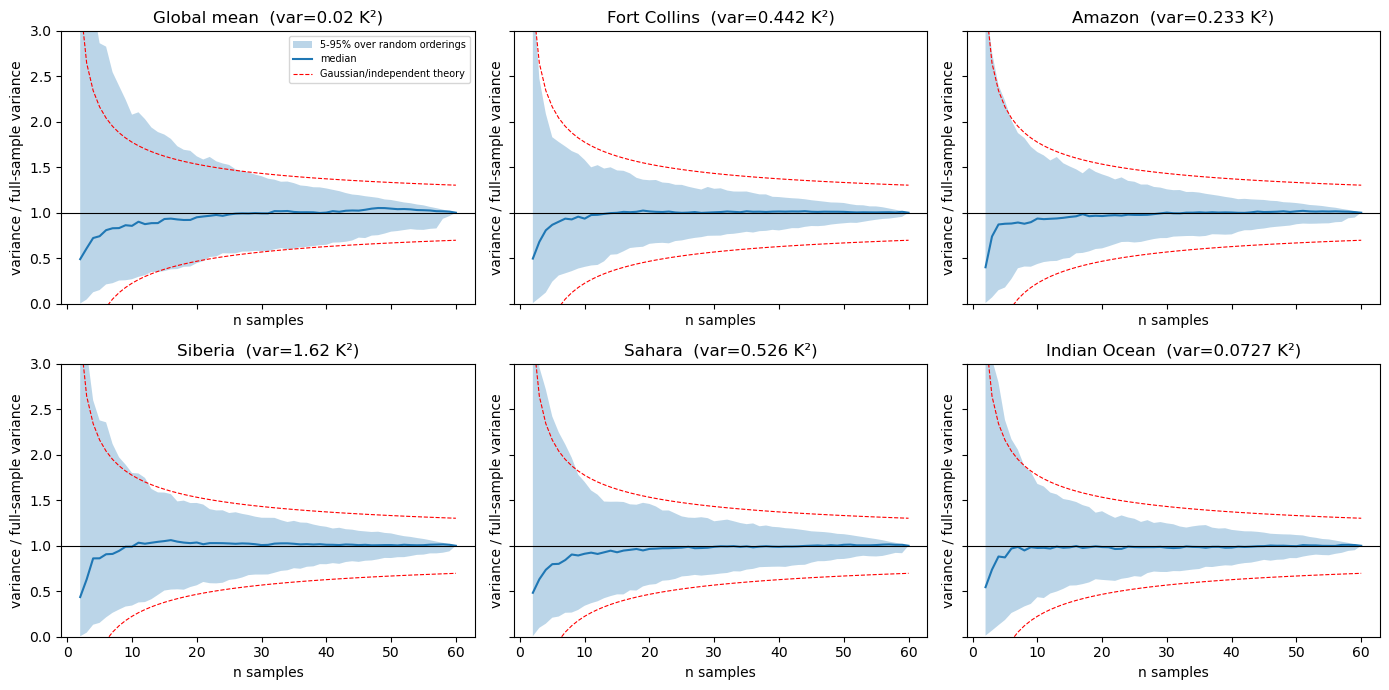

In [20]:
locations = {                       # edit freely; (lat, lon)
    "Fort Collins": (40.6, -105.1),
    "Amazon":       (-3.0, -60.0),
    "Siberia":      (62.0, 100.0),
    "Sahara":       (23.0, 10.0),
    "Indian Ocean": (-10.0, 80.0),  # will be NaN if your data is land-only
}

series = {"Global mean": stacked.weighted(weights).mean(("latitude", "longitude")).values}
for name, (lat, lon) in locations.items():
    series[name] = pick(stacked, lat, lon).values
names = list(series)
X = np.stack([series[k] for k in names], axis=1)          # (n, n_loc)

# The curve depends on the ORDER samples are added, so average over random orders.
# (Your stack order was year-major / ensemble-minor, so the first 6 samples were
# all one member - not what you want.)
n_perm = 300
rng = np.random.default_rng(42)
curves = np.empty((n_perm, n_total - 1, X.shape[1]))
for p in range(n_perm):
    curves[p] = cumvar(X[rng.permutation(n_total)])

ks = np.arange(2, n_total + 1)
ref = X.var(axis=0, ddof=1)                               # full-sample variance
rel = curves / ref
lo, med, hi = np.nanpercentile(rel, [5, 50, 95], axis=0)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
for j, ax in enumerate(axes.flat[:len(names)]):
    ax.fill_between(ks, lo[:, j], hi[:, j], alpha=0.3, label="5-95% over random orderings")
    ax.plot(ks, med[:, j], label="median")
    ax.axhline(1, color="k", lw=0.8)
    # Reference: Gaussian + independent samples => 90% interval of var ratio
    th = 1.645 * np.sqrt(2 / (ks - 1))
    ax.plot(ks, 1 + th, "r--", lw=0.8, label="Gaussian/independent theory")
    ax.plot(ks, 1 - th, "r--", lw=0.8)
    ax.set_title(f"{names[j]}  (var={ref[j]:.3g} K²)")
    ax.set_ylim(0, 3)
    ax.set_xlabel("n samples")
    ax.set_ylabel("variance / full-sample variance")
axes.flat[0].legend(fontsize=7)
plt.tight_layout()

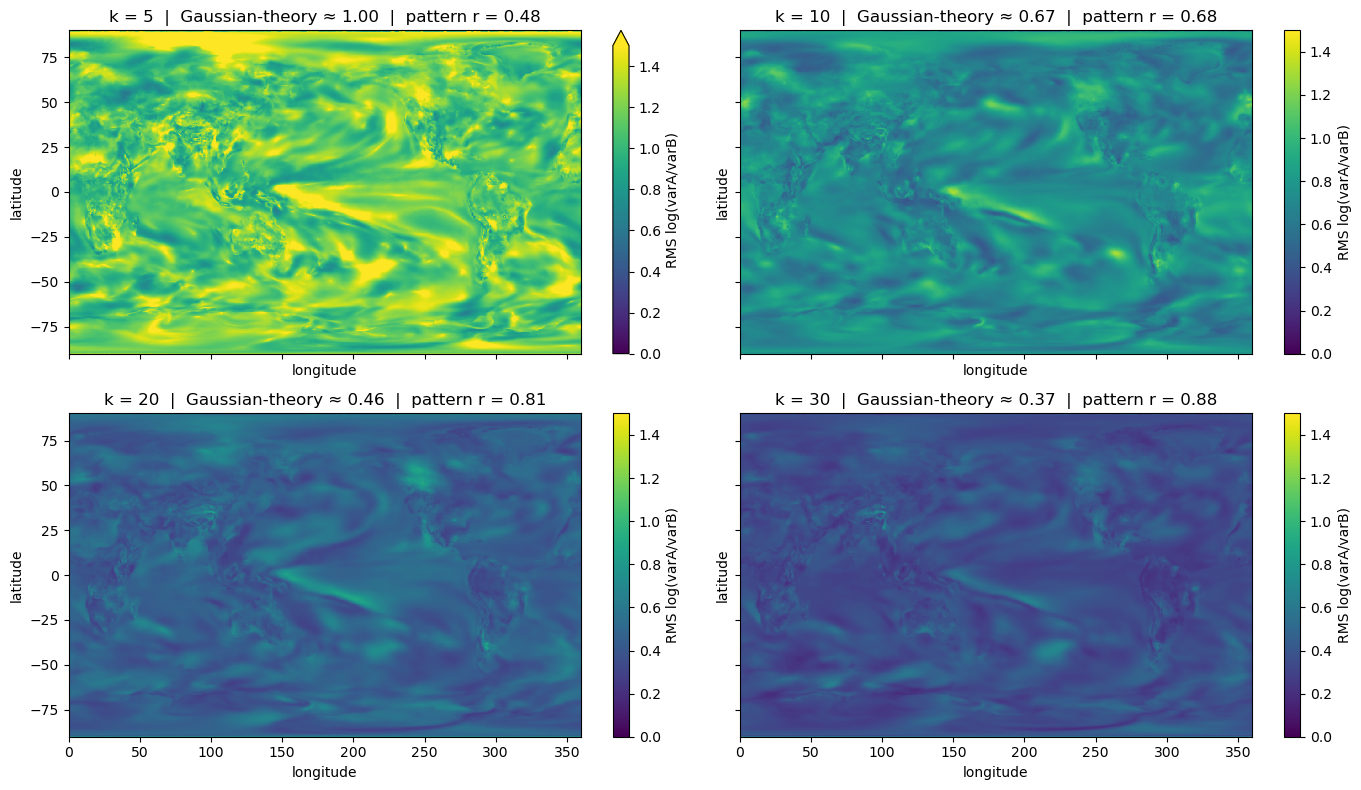

In [21]:
# %% 4. Maps: how reproducible is the variance field at sample size k? ---------
# Metric (avoids circularity of comparing a subset against the full set that
# contains it): draw two DISJOINT random subsets A, B of size k, compute the
# variance map of each, and measure how much they disagree.
#   rms_log_ratio = sqrt(mean_over_perms( log(varA/varB)^2 ))
# For Gaussian independent data the expected value is ~ sqrt(4/(k-1)) everywhere.
# Needs k <= n/2.
map_ks = [5, 10, 20, 30]
map_ks = [k for k in map_ks if 2 * k <= n_total]
n_perm_map = 40
vals = stacked.values.astype(np.float32)

sumsq = {k: np.zeros(vals.shape[1:], dtype=np.float64) for k in map_ks}
corr  = {k: [] for k in map_ks}
rng = np.random.default_rng(1)
for p in range(n_perm_map):
    perm = rng.permutation(n_total)
    for k in map_ks:
        vA = vals[perm[:k]].var(axis=0, ddof=1, dtype=np.float64)
        vB = vals[perm[k:2 * k]].var(axis=0, ddof=1, dtype=np.float64)
        with np.errstate(divide="ignore", invalid="ignore"):
            sumsq[k] += np.log(vA / vB) ** 2
        m = np.isfinite(vA) & np.isfinite(vB)
        corr[k].append(np.corrcoef(vA[m], vB[m])[0, 1])   # pattern reproducibility

coords = {"latitude": stacked.latitude, "longitude": stacked.longitude}
err_maps = {k: xr.DataArray(np.sqrt(sumsq[k] / n_perm_map), coords=coords, dims=("latitude", "longitude"))
            for k in map_ks}

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, k in zip(axes.flat, map_ks):
    err_maps[k].plot(ax=ax, vmin=0, vmax=1.5, cmap="viridis",
                     cbar_kwargs={"label": "RMS log(varA/varB)"})
    ax.set_title(f"k = {k}  |  Gaussian-theory ≈ {np.sqrt(4/(k-1)):.2f}  |  "
                 f"pattern r = {np.mean(corr[k]):.2f}")
plt.tight_layout()

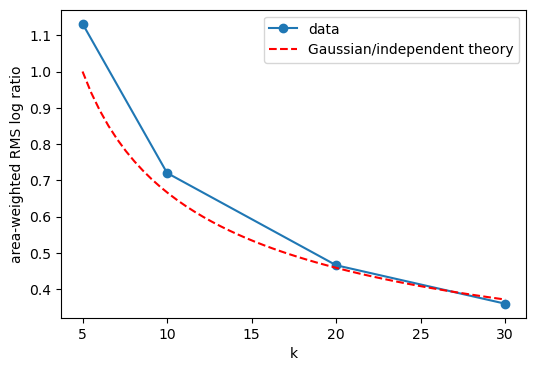

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
w2d = weights.broadcast_like(err_maps[map_ks[0]])
summary = [float(err_maps[k].weighted(w2d.fillna(0)).mean()) for k in map_ks]
ax.plot(map_ks, summary, "o-", label="data")
kk = np.linspace(min(map_ks), max(map_ks), 50)
ax.plot(kk, np.sqrt(4 / (kk - 1)), "r--", label="Gaussian/independent theory")
ax.set_xlabel("k"); ax.set_ylabel("area-weighted RMS log ratio"); ax.legend()

Text(0.5, 1.0, 'Interannual std dev, n=60')

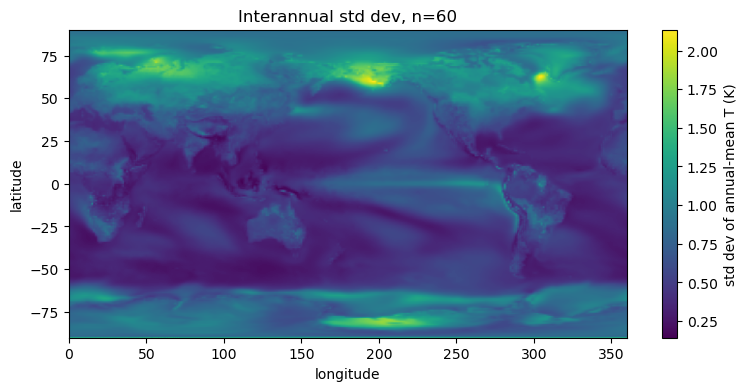

In [23]:
std_map = stacked.std("n", ddof=1)
std_map.plot(figsize=(9, 4), cbar_kwargs={"label": "std dev of annual-mean T (K)"})
plt.title(f"Interannual std dev, n={n_total}")